# Hyperspectral Image Classification with CNN and Transformer

**Author:** Alessandro Carotenuto  
**Student ID:** 1847282  
**Dataset:** Pavia University  
**Main Reference Paper:** [CNN-Transformer and Channel-Spatial Attention based network for hyperspectral image classification with few samples](https://www.sciencedirect.com/science/article/pii/S0893608025001625/pdfft?md5=230d33c76c4e035ccd0989aa0e02c9eb&pid=1-s2.0-S0893608025001625-main.pdf)  
**Github Repository:** [Github Repository](https://github.com/Alessandro-Carotenuto/Hyperspectral-Neural-Networks-Project)

## Project aim

The project aims to classify land-cover pixels in a hyperspectral image, with **limited amount of training examples**

A spatial-spectral patch centered on each labeled pixel is used as input.
A **CNN** learns local features, while a lightweight **Transformer** models non-local context.  
Channel Spatial Attention & Sample Amplification are introduced and a long process of ablations has been executed to find optimal configurations and isolate contibutions

The project is *expanded with a learned mask of pruning to reduce the input.*

### How does it work?

This **Notebook** imports the other python modules and generates the splits, imports the datasets, calls the class to create the architecture depending on the configuration, it can be imported in **Kaggle**, see next

## Setup 

This cell actually handles the possibility of running this notebook inside **Kaggle** or **locally**  

**To run this locally, nothing is needed.**  [*Just Configurate the experiment*](#architecture-and-training-configuration)

To run this on Kaggle (like i did mostly):
- Create a new notebook on kaggle
- Import the **Pavia University dataset** as input, there are many uplaoded versions on kaggle like the one i used: [Here](https://www.kaggle.com/datasets/syamkakarla/pavia-university-hsi)  
- **Import** this notebook
- **Activate Internet Connection**
- **Configurate** the training
- **Run the training**

If it's on Kaggle, it will **clone** my repository and set up the paths

In [ ]:
### Runtime and project source

from pathlib import Path
import importlib
import inspect
import subprocess
import sys
import numpy as np
import torch
import torch.nn as nn
from scipy.io import loadmat

# LOCATE PROJECT SOURCE
LOCAL_PROJECT_ROOT = Path.cwd().resolve()

REQUIRED_PROJECT_MODULES = (
    "data.py",
    "evaluation.py",
    "models.py",
    "plotting.py",
    "training.py",
    "utils.py",
)

KAGGLE_REPOSITORY_URL = (
    "https://github.com/Alessandro-Carotenuto/"
    "Hyperspectral-Neural-Networks-Project.git"
)

KAGGLE_PROJECT_ROOT = Path("/kaggle/working/project-source")
IS_KAGGLE = Path("/kaggle/input").is_dir()



def has_project_modules(directory):
    """RETURN TRUE IF ALL MODULES ARE PRESENT IN THE DIRECTORY"""
    return all((directory / name).is_file() for name in REQUIRED_PROJECT_MODULES)



def run_git(*arguments):
    """USING A SUBPROCESS TO RUN A GIT COMMAND"""
    return subprocess.run(
        ["git", *arguments],
        check=True,
        capture_output=True,
        text=True,
        timeout=180,
    )


def get_kaggle_project_root():
    """First Run for cloning the project source on Kaggle, then update it on subsequent runs
    
    Note to self: 
    -c is for running git commands in a specific directory, 
    --ff-only is for fast-forward only updates, 
    --depth 1 is for shallow cloning
    --branch main is for cloning the main branch."""


    if KAGGLE_PROJECT_ROOT.exists():
        run_git("-C", str(KAGGLE_PROJECT_ROOT),"pull", "--ff-only", "origin", "main")
    else:
        run_git("clone", "--depth", "1", "--branch", "main",KAGGLE_REPOSITORY_URL, str(KAGGLE_PROJECT_ROOT))

    if not has_project_modules(KAGGLE_PROJECT_ROOT):
        raise ModuleNotFoundError(f"MISSING MODULES FROM {KAGGLE_PROJECT_ROOT}.")
    return KAGGLE_PROJECT_ROOT


if IS_KAGGLE:
    source_root = get_kaggle_project_root()
else:
    source_root = LOCAL_PROJECT_ROOT
    if not has_project_modules(source_root):
        raise ModuleNotFoundError(
            f"Project modules were not found in {source_root}. "
            "Run the notebook with the project root as its working directory."
        )


# ADD PROJECT SOURCE TO PYTHON PATH
# SO I CAN IMPORT MODULES WITHOUT THE WHOLE PATH
source_root = source_root.resolve()
source_root_string = str(source_root)

if source_root_string in sys.path:
    sys.path.remove(source_root_string)
sys.path.insert(0, source_root_string)

# FOLDR TO SAVE OUTPUTS, MODELS, AND PLOTS
project_root = Path("/kaggle/working") if IS_KAGGLE else source_root


### Project imports


In [ ]:
from data import (
    create_dataloaders,
    create_few_shot_split,
    create_patch_datasets,
    create_run_datasets,
    extract_patch,
    normalize_per_band,
    reflect_pad_spatially,
    split_counts_by_class,
)
from evaluation import (
    aggregate_classification_metrics,
    calculate_classification_metrics,
    build_classification_map,
    build_evaluation_report,
    evaluate_checkpoint,
    predict_classes,
    save_evaluation_report,
)
from models import (
    build_compact_pruned_model,
    build_model,
)
from plotting import (
    plot_classification_map,
    plot_confusion_matrix,
    plot_pruning_mask,
    plot_training_curves,
)
# Reload training after clone/pull so a live Kaggle kernel cannot keep old code.
if "training" in sys.modules:
    loaded_training_path = Path(
        getattr(sys.modules["training"], "__file__", "")
    ).resolve()
    try:
        loaded_training_path.relative_to(source_root.resolve())
    except ValueError:
        del sys.modules["training"]
importlib.invalidate_caches()
import training as training_module
training_module = importlib.reload(training_module)
required_parameters = {
    training_module.build_checkpoint_path: {"weight_decay"},
    training_module.fit_model: {"weight_decay", "pruning_controller"},
}
for function, required in required_parameters.items():
    if not required.issubset(inspect.signature(function).parameters):
        raise RuntimeError(
            f"Loaded stale training code from {training_module.__file__}. "
            "Restart the Kaggle session and rerun the setup cell."
        )
AdaptivePruningController = training_module.AdaptivePruningController
build_checkpoint_path = training_module.build_checkpoint_path
build_training_seeds = training_module.build_training_seeds
configure_reproducibility = training_module.configure_reproducibility
fit_model = training_module.fit_model
from utils import (
    ConformerCNNNormalization,
    DataSplitType,
    InputNormalization,
    LRSchedulingType,
    ModelArchitecture,
    PatchSize,
    PaviaClass,
    SampleAmplificationMode,
    SplitName,
    TrainingSeedMode,
    TransformerPositionEncoding,
)



### DATASET PATHS AND LOADING


Locate Pavia University data on Kaggle or in the local `data/raw` directory.


In [ ]:
# FIND PAVIA FILES ON KAGGLE 
if IS_KAGGLE:
    kaggle_input_dir = Path("/kaggle/input")
    cube_matches = list(kaggle_input_dir.rglob("PaviaU.mat"))
    ground_truth_matches = list(kaggle_input_dir.rglob("PaviaU_gt.mat"))

    if len(cube_matches) != 1 or len(ground_truth_matches) != 1:
        raise FileNotFoundError(
            "Expected one PaviaU.mat and one PaviaU_gt.mat under "
            f"{kaggle_input_dir}; found {len(cube_matches)} and "
            f"{len(ground_truth_matches)}. Attach the Pavia dataset."
        )

    cube_path = cube_matches[0]
    ground_truth_path = ground_truth_matches[0]

# FIND PAVIA FILES LOCALLY
else:
    local_data_dir = project_root / "data" / "raw"
    cube_path = local_data_dir / "PaviaU.mat"
    ground_truth_path = local_data_dir / "PaviaU_gt.mat"

for input_path in (cube_path, ground_truth_path):
    if not input_path.is_file():
        raise FileNotFoundError(f"Dataset file not found: {input_path}")


# LOAD MATLAB FILES
cube = loadmat(cube_path)["paviaU"]
ground_truth = loadmat(ground_truth_path)["paviaU_gt"]
print("Cube:", cube.shape)
print("Ground truth:", ground_truth.shape)


### ARCHITECTURE AND TRAINING CONFIGURATION


In [ ]:
MODEL_VARIANT = "NAME OF THE MODEL VARIANT"
# DATA AND FEW-SHOT SPLIT

SPLIT_SEED = 42
DATA_SPLIT_TYPE = DataSplitType.RANDOM 

# DATA SPLIT TYPES AND MEANING:
# -RANDOM:                      random pixel split; patches can overlap spatially
# -RANDOM_NO_CENTER_OVERLAP:    exclude test centers inside training patches
# -RANDOM_NO_OVERLAP:           keep training and test patch footprints separate

TRAIN_SAMPLES_PER_CLASS = 10
VALIDATION_SAMPLES_PER_CLASS = 5

NUM_CLASSES = len(PaviaClass) - 1 #Exclude the UNLABELED class from the count of classes

LABELED_CLASS_IDS = tuple(
    int(label) for label in PaviaClass
    if label != PaviaClass.UNLABELED
)

class_names = {int(label): label.display_name for label in PaviaClass}

# PAVIA CLASS OPTIONS AND MEANING:
# IT ONLY CONTAINS THE CLASSES THAT ARE LABELED IN THE DATASET, EXCLUDING UNLABELED CLASS
# POSSIBLE TO EXCLUDE OTHERS ADDING THEM TO THE IF CONDITION 
# -UNLABELED (0):                 unlabeled pixel excluded from classification
# -ASPHALT (1):                   asphalt surface
# -MEADOWS (2):                   meadow vegetation
# -GRAVEL (3):                    gravel surface
# -TREES (4):                     tree cover
# -PAINTED_METAL_SHEETS (5):      painted metal roof
# -BARE_SOIL (6):                 bare soil
# -BITUMEN (7):                   bitumen surface
# -SELF_BLOCKING_BRICKS (8):      self-blocking brick surface
# -SHADOWS (9):                   shaded areas


# PATCHES SIZES AND PREPROCESSING

PATCH_SIZE = PatchSize.PAPER

# PATCH SIZE OPTIONS AND MEANING:
# -SMALLEST (7):                  7-by-7 spatial patch
# -SMALL (11):                    11-by-11 spatial patch
# -PAPER (15):                    15-by-15 spatial patch used in the paper
# -LARGE (19):                    19-by-19 spatial patch
# -LARGEST (23):                  23-by-23 spatial patch

PATCH_RADIUS = int(PATCH_SIZE) // 2

INPUT_NORMALIZATION = InputNormalization.MIN_MAX

# INPUT NORMALIZATION OPTIONS AND MEANING:
# -MIN_MAX:                       scales each spectral band to [0, 1]
# -Z_SCORE:                       centers each band at 0 and scales to unit standard deviation

# MODEL ARCHITECTURE
# Selects the classifier and its feature, Transformer, and pruning settings
# Pruning settings are used only by the experimental pruning architecture

ARCHITECTURE = ModelArchitecture.CNN_TRANSFORMER_CSA

MODEL_NAME = ARCHITECTURE.display_name
RUN_NAME = "full"

# MODEL ARCHITECTURE OPTIONS AND MEANING:
# -CNN_CSA:                                       multiscale CNN with channel-spatial attention
# -CNN_TRANSFORMER:                               parallel CNN and Transformer branches
# -CNN_TRANSFORMER_CSA:                           CNN-Transformer with channel-spatial attention
# -CNN_TRANSFORMER_CSA_BAND_PRUNING:              adds adaptive raw-band gates and pruning

FEATURE_CHANNELS = 128
TRANSFORMER_HEADS = 4
TRANSFORMER_FFN_EXPANSION = 4
TRANSFORMER_FFN_RESIDUAL_SCALE = 0.5

TRANSFORMER_POSITION_ENCODING = TransformerPositionEncoding.LEARNED_2D

# TRANSFORMER POSITION ENCODING OPTIONS AND MEANING:
# -LEARNED_2D:                    learned relative bias over 2D patch offsets
# -CONFORMER_1D:                  relative position encoding over flattened patch tokens, like the Conformer paper

TRANSFORMER_CNN_NORMALIZATION = ConformerCNNNormalization.BATCH_NORM

# CONFORMER CNN NORMALIZATION OPTIONS AND MEANING:
# -BATCH_NORM:                    normalizes activations across the batch
# -LAYER_NORM:                    normalizes activations across channels per sample

TRANSFORMER_DROPOUT = 0.1           

# PRUNING SETTINGS, if NO PRUNING WANTED, SET PRUNING_PERCENTAGE = 0.0 (default)

PRUNING_PERCENTAGE = 0.0            # Percentage of raw spectral bands to prune in the pruning architecture
PRUNING_GATE_SLOPE = 20.0           # Slope of the sigmoid function used to gate raw spectral bands in the pruning architecture
PRUNING_SPARSITY_WEIGHT = 0.001     # Weight of the sparsity loss term that encourages pruning in the pruning architecture
PRUNING_FINETUNE_EPOCHS = 30        # Set to 0 to skip compact-model fine-tuning

# SAMPLE AMPLIFICATION
# Augments training patches; validation and test patches remain unchanged

SAMPLE_AMPLIFICATION_MODE = SampleAmplificationMode.CTA_NET

# SAMPLE AMPLIFICATION MODE OPTIONS AND MEANING:
# -DISABLED:                      uses the original training patches only
# -CTA_NET:                       adds noisy, rotated, and same-class summed patches

# Sample amplification settings for the CTA-Net augmentation, reasonable values
SA_CENTRAL_REGION_SIZE = 3
SA_GAUSSIAN_NOISE_STD = 0.04

# TRAINING AND OPTIMIZATION
# Controls the training duration, optimizer, learning rate, and saved reports

EPOCHS = 150                    #Matches the number of epochs used in the original paper for training the model

LEARNING_RATE = 0.00008
WEIGHT_DECAY = 0.0

LR_SCHEDULING = LRSchedulingType.FIXED

# LR SCHEDULING TYPE OPTIONS AND MEANING:
# -FIXED:                         keeps the learning rate constant
# -COSINEANNEALING:               reduces the learning rate with a cosine schedule

EVALUATION_PROGRESS_EVERY = 100
SAVE_EVALUATION_REPORT = True

# TRAINING SEEDS
# Choose one fixed seed or a fixed/random list for repeated runs
# Reuse a printed seed list to compare configurations with the same seeds

TRAINING_SEED_MODE = TrainingSeedMode.ONE_FIXED_TRAIN_SEED

# TRAINING SEED MODE OPTIONS AND MEANING:
# -ONE_FIXED_TRAIN_SEED:          runs once with TRAINING_SEED_FIXED
# -MULTI_FIXED_TRAIN_SEED:        reuses the seed list in TRAINING_SEEDS_FIXED
# -MULTI_RANDOM_TRAIN_SEED:       generates a fresh random seed list

TRAINING_SEED_FIXED = 100
NUM_SEEDS = 10
TRAINING_SEEDS_FIXED = []

# RUNTIME
# Sets batch loading and selects a GPU when available, otherwise the CPU
BATCH_SIZE = 32
NUM_WORKERS = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")



### Configuration summary


In [ ]:
print("Cube:", cube_path)
print("Ground truth:", ground_truth_path)
print("Runtime:", "Kaggle" if IS_KAGGLE else "local")
print("Patch size:", int(PATCH_SIZE))
print("Architecture:", ARCHITECTURE.display_name)
print("Model variant:", MODEL_VARIANT)
if ARCHITECTURE.uses_transformer:
    print("Transformer heads:", TRANSFORMER_HEADS)
    print(
        "Transformer FFN residual scale:",
        TRANSFORMER_FFN_RESIDUAL_SCALE,
    )
    print(
        "Transformer position encoding:",
        TRANSFORMER_POSITION_ENCODING.value,
    )
    print(
        "Transformer CNN normalization:",
        TRANSFORMER_CNN_NORMALIZATION.value,
    )
print("Split seed:", SPLIT_SEED)
print("Data split:", DATA_SPLIT_TYPE.value)
training_seeds = build_training_seeds(
    TRAINING_SEED_MODE,
    TRAINING_SEED_FIXED,
    NUM_SEEDS,
    fixed_seeds=TRAINING_SEEDS_FIXED,
)
print("Training seed mode:", TRAINING_SEED_MODE.value)
print("Training seeds:", training_seeds)
print(f"TRAINING_SEEDS_FIXED = {training_seeds}")
print("Selected device:", DEVICE)
print("Input normalization:", INPUT_NORMALIZATION.value)
print("Pruning gate slope:", PRUNING_GATE_SLOPE)
print("Pruning sparsity weight:", PRUNING_SPARSITY_WEIGHT)
print("Pruning percentage:", PRUNING_PERCENTAGE)
print("Compact pruning fine-tune epochs:", PRUNING_FINETUNE_EPOCHS)
print("Sample amplification:", SAMPLE_AMPLIFICATION_MODE.value)


## SPLIT GENERATION, DATALOADING, PREPROCESSING


### GENERATE AND SAVE FEW-SHOT COORDINATE SPLIT


In [ ]:
split_tables = create_few_shot_split(
    ground_truth,
    LABELED_CLASS_IDS,
    seed=SPLIT_SEED,
    train_samples_per_class=TRAIN_SAMPLES_PER_CLASS,
    validation_samples_per_class=VALIDATION_SAMPLES_PER_CLASS,
    split_type=DATA_SPLIT_TYPE,
    patch_radius=PATCH_RADIUS,
)
split_counts = split_counts_by_class(
    split_tables, LABELED_CLASS_IDS
)

for label in LABELED_CLASS_IDS:
    counts_for_label = split_counts[label]
    print(
        f"{label}: {class_names[label]} - "
        f"train {counts_for_label['train']}, "
        f"validation {counts_for_label['validation']}, "
        f"test {counts_for_label['test']}, "
        f"excluded {counts_for_label['excluded']}"
    )

expected_train_samples = len(split_tables[SplitName.TRAIN.value])
expected_validation_samples = len(
    split_tables[SplitName.VALIDATION.value]
)
expected_test_samples = len(split_tables[SplitName.TEST.value])

split_directory = project_root / "data" / "splits" / f"seed_{SPLIT_SEED}"
split_directory.mkdir(parents=True, exist_ok=True)
split_suffix = (
    ""
    if DATA_SPLIT_TYPE == DataSplitType.RANDOM
    else f"_{DATA_SPLIT_TYPE.value}"
)
for split_name, split_table in split_tables.items():
    split_path = split_directory / f"{split_name}{split_suffix}.csv"
    np.savetxt(
        split_path,
        split_table,
        fmt="%d",
        delimiter=",",
        header="row,column,label",
        comments="",
    )
    print(f"Saved {len(split_table)} samples to {split_path}")


### INPUT NORMALIZATION

In [ ]:
# Check output shape, dtype, and the selected per-band normalization.
normalized_cube = normalize_per_band(cube, INPUT_NORMALIZATION)
assert normalized_cube.shape == cube.shape
assert normalized_cube.dtype == np.float32
assert not np.shares_memory(normalized_cube, cube)

if INPUT_NORMALIZATION == InputNormalization.MIN_MAX:
    assert np.allclose(normalized_cube.min(axis=(0, 1)), 0.0)
    assert np.allclose(normalized_cube.max(axis=(0, 1)), 1.0)
elif INPUT_NORMALIZATION == InputNormalization.Z_SCORE:
    assert np.allclose(normalized_cube.mean(axis=(0, 1)), 0.0, atol=1e-5)
    assert np.allclose(normalized_cube.std(axis=(0, 1)), 1.0, atol=1e-5)


### Reflect Padding

In [ ]:
# Check padding adds the expected border and preserves the original cube.
padded_cube = reflect_pad_spatially(normalized_cube, PATCH_RADIUS)
expected_padded_shape = (
    normalized_cube.shape[0] + 2 * PATCH_RADIUS,
    normalized_cube.shape[1] + 2 * PATCH_RADIUS,
    normalized_cube.shape[2],
)
restored_normalized_cube = padded_cube[PATCH_RADIUS:-PATCH_RADIUS, PATCH_RADIUS:-PATCH_RADIUS, :]
assert padded_cube.shape == expected_padded_shape
assert padded_cube.dtype == normalized_cube.dtype
assert np.array_equal(restored_normalized_cube, normalized_cube)


### PyTorch Patch Dataset

This portion of the code reads the CSV file with the saved split and from the normalized and padded data, estracts patch of the wanted size, adjust for model class logits.

We also convert numeric types to float32 and we use *ascontigousarray* for efficiency

In [ ]:
datasets = create_patch_datasets(padded_cube, split_tables, PATCH_SIZE, NUM_CLASSES)
train_dataset = datasets[SplitName.TRAIN.value]
validation_dataset = datasets[SplitName.VALIDATION.value]
test_dataset = datasets[SplitName.TEST.value]

example_patch, _ = train_dataset[0]
example_row, example_column = train_dataset.coordinates[0]

assert len(train_dataset) == expected_train_samples
assert len(validation_dataset) == expected_validation_samples
assert len(test_dataset) == expected_test_samples
expected_center_spectrum = torch.from_numpy(normalized_cube[example_row, example_column, :])
assert torch.equal(example_patch[:, PATCH_RADIUS, PATCH_RADIUS], expected_center_spectrum)


### PyTorch DataLoaders

In [ ]:
dataloaders = create_dataloaders(
    datasets,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    training_seed=training_seeds[0],
)

train_loader = dataloaders[SplitName.TRAIN.value]
validation_loader = dataloaders[SplitName.VALIDATION.value]
test_loader = dataloaders[SplitName.TEST.value]

batch_patches, batch_targets = next(iter(validation_loader))
expected_batch_size = min(BATCH_SIZE, len(validation_dataset))
train_class_counts = np.bincount(train_dataset.targets, minlength=NUM_CLASSES)

expected_batch_shape = (
    expected_batch_size, cube.shape[2], int(PATCH_SIZE), int(PATCH_SIZE)
)
assert batch_patches.shape == expected_batch_shape
assert batch_targets.shape == (expected_batch_size,)
assert batch_patches.dtype == torch.float32
assert batch_targets.dtype == torch.long
assert batch_targets.min() >= 0
assert batch_targets.max() < NUM_CLASSES
assert np.array_equal(train_class_counts, np.full(NUM_CLASSES, TRAIN_SAMPLES_PER_CLASS))

print("Batches per epoch:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))


## Model Architecture

### CNN, TRANSFORMER, CT AND CSA BLOCKS

The CNN branch returns only its fused multiscale features. The single CT residual is applied after CNN-Transformer fusion, as shown in the paper. For spatial attention, this notebook follows the detailed text in Section 2.4: an extrema branch (`max`, `min`) and a distribution branch (`mean`, `std`) use `5 x 5` convolutions and PReLU, followed by concatenation and a `1 x 1` fusion convolution. Every block preserves `(B, C, H, W)`.

### Network Creation

In [ ]:
MODEL_ARGUMENTS = {
    "input_channels": cube.shape[2],
    "feature_channels": FEATURE_CHANNELS,
    "num_classes": NUM_CLASSES,
    "patch_size": PATCH_SIZE,
    "transformer_heads": TRANSFORMER_HEADS,
    "transformer_expansion_factor": TRANSFORMER_FFN_EXPANSION,
    "transformer_dropout": TRANSFORMER_DROPOUT,
    "transformer_ffn_residual_scale": TRANSFORMER_FFN_RESIDUAL_SCALE,
    "transformer_position_encoding": TRANSFORMER_POSITION_ENCODING,
    "transformer_cnn_normalization": TRANSFORMER_CNN_NORMALIZATION,
    "pruning_gate_slope": PRUNING_GATE_SLOPE,
    "pruning_sparsity_weight": PRUNING_SPARSITY_WEIGHT,
    "pruning_percentage": PRUNING_PERCENTAGE,
}


def build_configured_model():
    model = build_model(ARCHITECTURE, **MODEL_ARGUMENTS)
    return model



### Forward and Backward Sanity Check

In [ ]:
# ONE TRAINING PATCH FOR EACH CLASS

sanity_indices = [
    np.flatnonzero(train_dataset.targets == class_index)[0]
    for class_index in range(NUM_CLASSES)
]
sanity_samples = [train_dataset[int(index)] for index in sanity_indices]
sanity_patches = torch.stack([sample[0] for sample in sanity_samples])
sanity_targets = torch.stack([sample[1] for sample in sanity_samples])

# RUN ONE FORWARD AND BACKWARD PASS TO CHECK GRADIENTS
torch.manual_seed(training_seeds[0])
sanity_model = build_configured_model()
sanity_model.train()
criterion = nn.CrossEntropyLoss()
sanity_logits = sanity_model(sanity_patches)
sanity_loss = criterion(sanity_logits, sanity_targets)
sanity_loss.backward()

gradients = [p.grad for p in sanity_model.parameters() if p.grad is not None]
gradient_norm = sum(gradient.norm().item() for gradient in gradients)

# CHECK CLASS ORDER, OUTPUT SHAPE, LOSS, AND GRADIENTS
assert torch.equal(sanity_targets, torch.arange(NUM_CLASSES))
assert sanity_logits.shape == (NUM_CLASSES, NUM_CLASSES)
assert torch.isfinite(sanity_loss)
assert gradients
assert all(torch.isfinite(gradient).all() for gradient in gradients)
assert gradient_norm > 0

sanity_model.zero_grad(set_to_none=True)
print("Forward/backward check passed; gradient norm:", gradient_norm)


## Model Training


### RUN METADATA AND CHECKPOINT PATHS

In [ ]:
# PREPARE MODEL ARGUMENTS FOR THE SAVED REPORT
MODEL_ARGUMENTS_FOR_REPORT = {
    **MODEL_ARGUMENTS,
    "patch_size": int(PATCH_SIZE),
    "transformer_position_encoding": TRANSFORMER_POSITION_ENCODING.value,
    "transformer_cnn_normalization": TRANSFORMER_CNN_NORMALIZATION.value,
}

# CHECKPOINT FILE NAMING OPTIONS
CHECKPOINT_DIRECTORY = project_root / "outputs" / "checkpoints"
CHECKPOINT_ARGUMENTS = {
    "architecture": ARCHITECTURE,
    "transformer_heads": TRANSFORMER_HEADS,
    "transformer_expansion_factor": TRANSFORMER_FFN_EXPANSION,
    "transformer_dropout": TRANSFORMER_DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "transformer_ffn_residual_scale": TRANSFORMER_FFN_RESIDUAL_SCALE,
    "transformer_position_encoding": TRANSFORMER_POSITION_ENCODING,
    "transformer_cnn_normalization": TRANSFORMER_CNN_NORMALIZATION,
    "pruning_gate_slope": PRUNING_GATE_SLOPE,
    "pruning_sparsity_weight": PRUNING_SPARSITY_WEIGHT,
    "pruning_percentage": PRUNING_PERCENTAGE,
    "input_normalization": INPUT_NORMALIZATION,
    "model_variant": MODEL_VARIANT,
    "run_name": RUN_NAME,
    "patch_size": PATCH_SIZE,
    "epochs": EPOCHS,
    "feature_channels": FEATURE_CHANNELS,
    "scheduling_type": LR_SCHEDULING,
    "split_seed": SPLIT_SEED,
    "split_type": DATA_SPLIT_TYPE,
    "sample_amplification_mode": SAMPLE_AMPLIFICATION_MODE,
}

# CONFIGURATION SAVED WITH EACH CHECKPOINT AND REPORT
BASE_EXPERIMENT_CONFIGURATION = {
    "dataset": "Pavia University",
    "model": MODEL_NAME,
    "architecture": ARCHITECTURE.value,
    "model_variant": MODEL_VARIANT,
    "split_seed": SPLIT_SEED,
    "data_split_type": DATA_SPLIT_TYPE.value,
    "model_arguments": MODEL_ARGUMENTS_FOR_REPORT,
    "pruning_finetune_epochs": (
        PRUNING_FINETUNE_EPOCHS
        if ARCHITECTURE.uses_adaptive_pruning
        else 0
    ),
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "lr_scheduling": LR_SCHEDULING.value,
    "epochs_requested": EPOCHS,
    "normalization": INPUT_NORMALIZATION.value,
    "padding": "reflect",
    "run_mode": RUN_NAME,
}

RUN_CONFIGURATIONS = []

for training_seed in training_seeds:
    RUN_CONFIGURATIONS.append(
        {
            "training_seed": training_seed,
            "checkpoint_path": build_checkpoint_path(
                CHECKPOINT_DIRECTORY,
                **CHECKPOINT_ARGUMENTS,
                training_seed=training_seed,
            ),
            "configuration": {
                **BASE_EXPERIMENT_CONFIGURATION,
                "training_seed_mode": TRAINING_SEED_MODE.value,
                "training_seed": training_seed,
            },
        }
    )


### Model Training

In [ ]:
# Train one independent model for each configured seed.

training_runs = []

# TRAINING LOOP
# LOOPS THROUGH EACH CONFIGURATION IN RUN_CONFIGURATIONS, SETS THE SEED, CREATES DATASETS AND DATALOADERS, BUILDS THE MODEL, TRAINS IT, AND SAVES THE RESULTS.
for run_index, run_configuration in enumerate(RUN_CONFIGURATIONS, start=1): 
    training_seed = run_configuration["training_seed"]
    
    print(
        f"\n=== Training run {run_index}/{len(training_seeds)} "
        f"| seed {training_seed} ==="
    )
   
    configure_reproducibility(training_seed) # THIS ENSURES THAT EACH TRAINING RUN IS REPRODUCIBLE AND INDEPENDENT
   
    # DATA AND DATALOADERS
    # Create a new set of train,val,test sets for this run, with sample amplification if enabled

    run_datasets = create_run_datasets(
        datasets,
        sample_amplification_mode=SAMPLE_AMPLIFICATION_MODE,
        training_seed=training_seed,
        central_region_size=SA_CENTRAL_REGION_SIZE,
        gaussian_noise_standard_deviation=SA_GAUSSIAN_NOISE_STD,
    )

    # SELECT THIS TRAINING SPLIT
    run_train_dataset = run_datasets[SplitName.TRAIN.value]
    print("Training samples for this run:", len(run_train_dataset))

    run_dataloaders = create_dataloaders(
        run_datasets,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
        training_seed=training_seed,
    )

    # MODEL
    model = build_configured_model().to(DEVICE)
    checkpoint_path = run_configuration["checkpoint_path"]
    experiment_configuration = run_configuration["configuration"]
    experiment_configuration["sample_amplification"] = getattr(run_train_dataset,"amplification_metadata",{"mode": SampleAmplificationMode.DISABLED.value})

    # TRAIN MODEL

    pruning_controller = (
        AdaptivePruningController(model)
        if ARCHITECTURE.uses_adaptive_pruning
        else None
    )

    # TRAINING LOOP
    # FITS THE MODEL TO THE TRAINING DATA, EVALUATES ON VALIDATION DATA
    
    training_result = fit_model(
        model,
        run_dataloaders[SplitName.TRAIN.value],
        run_dataloaders[SplitName.VALIDATION.value],
        DEVICE,
        epochs=EPOCHS,
        learning_rate=LEARNING_RATE,
        scheduling_type=LR_SCHEDULING,
        weight_decay=WEIGHT_DECAY,
        checkpoint_path=checkpoint_path,
        checkpoint_metadata=experiment_configuration,
        pruning_controller=pruning_controller,
    )

    # OPTIONAL ADAPTIVE PRUNING, FINE TUNING, AND COMPACT MODEL CREATION

    mask_checkpoint_path = checkpoint_path
    if ARCHITECTURE.uses_adaptive_pruning:

        # Reload the trained model and read which spectral bands it retained.
        mask_checkpoint = torch.load(mask_checkpoint_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(mask_checkpoint["model_state_dict"])
        selected_band_indices = torch.as_tensor(mask_checkpoint["selected_band_indices"], dtype=torch.long)
        mean_band_gates = torch.as_tensor(mask_checkpoint["mean_band_gates"])

        # Save pruning details with this run's experiment metadata.
        experiment_configuration.update({
            "pruned_band_count": len(selected_band_indices),
            "selected_band_indices": selected_band_indices.tolist(),
            "mean_band_gates": mean_band_gates.tolist(),
            "pruning_finetune_epochs": PRUNING_FINETUNE_EPOCHS,
        })

        # Summarize the retained bands and the learned gate values.
        print("Retained spectral bands:", len(selected_band_indices), "/", cube.shape[2])
        print("Pruning target (%):", PRUNING_PERCENTAGE)
        gate_quantiles = np.quantile(mean_band_gates.numpy(), [0, .1, .25, .5, .75, .9, 1])
        print(
            "Mean gate quantiles [min, 10%, 25%, 50%, 75%, 90%, max]:",
            gate_quantiles.round(4).tolist(),
        )

        # IF PRUNING IS EBABLED AND FINE-TUNING IS REQUESTED, CREATE A COMPACT MODEL AND FINE-TUNE IT
        if PRUNING_FINETUNE_EPOCHS > 0:

            # Build a smaller model that uses only the retained spectral bands.
            compact_model = build_compact_pruned_model(model, selected_band_indices).to(DEVICE)
            compact_checkpoint_path = mask_checkpoint_path.with_name(mask_checkpoint_path.stem + "_compact.pt")
            configure_reproducibility(training_seed)

            # Keep the original run metadata and identify this fine-tuning phase.
            compact_checkpoint_metadata = {
                **experiment_configuration,
                "training_phase": "compact_pruning_finetune",
                "mask_checkpoint_path": str(mask_checkpoint_path),
            }

            # Fine-tune and save the compact model as a separate checkpoint.
            compact_training_result = fit_model(
                compact_model,
                run_dataloaders[SplitName.TRAIN.value],
                run_dataloaders[SplitName.VALIDATION.value],
                DEVICE,
                epochs=PRUNING_FINETUNE_EPOCHS,
                learning_rate=LEARNING_RATE,
                scheduling_type=LR_SCHEDULING,
                weight_decay=WEIGHT_DECAY,
                checkpoint_path=compact_checkpoint_path,
                checkpoint_metadata=compact_checkpoint_metadata,
            )
            training_result = compact_training_result
            checkpoint_path = compact_checkpoint_path
            del compact_model

    # SAVE RUN RESULTS

    training_run = {
        "seed": training_seed,
        "configuration": experiment_configuration,
        "checkpoint_path": checkpoint_path,
        "mask_checkpoint_path": (
            mask_checkpoint_path
            if ARCHITECTURE.uses_adaptive_pruning
            else None
        ),
        "training_result": training_result,
    }

    training_runs.append(training_run)
    print("Best epoch:", training_result["best_epoch"])
    print("Best validation loss:", training_result["best_validation_loss"])
    print("Checkpoint saved to:", checkpoint_path)
    del model, run_dataloaders, run_train_dataset, run_datasets

### Training Curves

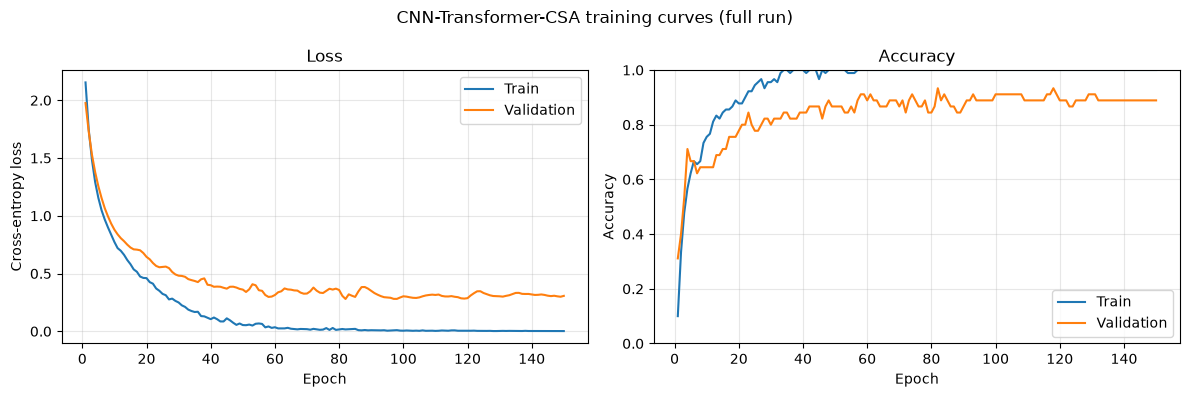

In [ ]:
for run in training_runs:
    plot_training_curves(run["training_result"]["history"],f"{RUN_NAME}_seed_{run['seed']}",MODEL_NAME)


## Model Evaluation

In [ ]:
# EVALUATE EACH TRAINING RUN

evaluation_runs = []
for run_index, run in enumerate(training_runs, start=1):
    training_seed = run["seed"]
    print(
        f"\n=== Evaluation run {run_index}/{len(training_runs)} "
        f"| seed {training_seed} ==="
    )

    model = build_configured_model().to(DEVICE)

    if ARCHITECTURE.uses_adaptive_pruning:
        # Load the best adaptive-pruning checkpoint and its selected bands.
        mask_checkpoint = torch.load(run["mask_checkpoint_path"], map_location=DEVICE, weights_only=False)
        model.load_state_dict(mask_checkpoint["model_state_dict"])
        selected_band_indices = torch.as_tensor(mask_checkpoint["selected_band_indices"], dtype=torch.long)
        mean_band_gates = torch.as_tensor(mask_checkpoint["mean_band_gates"])

        # Rebuild the compact model and restore its fine-tuned checkpoint if available.
        compact_model = build_compact_pruned_model(model, selected_band_indices).to(DEVICE)
        if run["configuration"].get("pruning_finetune_epochs", 0) > 0:
            checkpoint = torch.load(run["checkpoint_path"], map_location=DEVICE, weights_only=False)
            compact_model.load_state_dict(checkpoint["model_state_dict"])
        else:
            checkpoint = mask_checkpoint

        # Predict test classes with the compact model.
        targets, predictions = predict_classes(
            compact_model,
            test_loader,
            DEVICE,
            progress_every=EVALUATION_PROGRESS_EVERY,
            progress_label=f"Compact test evaluation seed {training_seed}",
        )

        evaluation_result = {
            "checkpoint": checkpoint,
            "targets": targets,
            "predictions": predictions,
            "metrics": calculate_classification_metrics(targets, predictions, NUM_CLASSES),
            "selected_band_indices": selected_band_indices.tolist(),
            "mean_band_gates": mean_band_gates.tolist(),
            "compact_model": compact_model,
        }

        # Save pruning details and plot the learned band scores.
        run["configuration"]["pruned_band_count"] = len(selected_band_indices)
        run["configuration"]["selected_band_indices"] = selected_band_indices.tolist()
        run["configuration"]["mean_band_gates"] = mean_band_gates.tolist()
        plot_pruning_mask(
            mean_band_gates.numpy(),
            selected_band_indices.numpy(),
            run_label=f"training seed {training_seed}",
        )
        model = compact_model
    else:

        # Evaluate the saved checkpoint directly for non-pruning architectures
        evaluation_result = evaluate_checkpoint(
            model,
            test_loader,
            run["checkpoint_path"],
            DEVICE,
            NUM_CLASSES,
            progress_every=EVALUATION_PROGRESS_EVERY,
            progress_label=f"Test evaluation seed {training_seed}",
        )

    # Store this run's predictions and report a short evaluation summary.
    assert len(evaluation_result["targets"]) == len(test_dataset)
    evaluation_runs.append({**run, "evaluation_result": evaluation_result})
    print("Loaded checkpoint epoch:", evaluation_result["checkpoint"]["epoch"])
    print("Checkpoint validation loss:", evaluation_result["checkpoint"]["validation_loss"])
    print("Test predictions:", len(evaluation_result["predictions"]))


Test evaluation: batch 1/1333 | samples 32/42641
Test evaluation: batch 100/1333 | samples 3200/42641
Test evaluation: batch 200/1333 | samples 6400/42641
Test evaluation: batch 300/1333 | samples 9600/42641
Test evaluation: batch 400/1333 | samples 12800/42641
Test evaluation: batch 500/1333 | samples 16000/42641
Test evaluation: batch 600/1333 | samples 19200/42641
Test evaluation: batch 700/1333 | samples 22400/42641
Test evaluation: batch 800/1333 | samples 25600/42641
Test evaluation: batch 900/1333 | samples 28800/42641
Test evaluation: batch 1000/1333 | samples 32000/42641
Test evaluation: batch 1100/1333 | samples 35200/42641
Test evaluation: batch 1200/1333 | samples 38400/42641
Test evaluation: batch 1300/1333 | samples 41600/42641
Test evaluation: batch 1333/1333 | samples 42641/42641
Loaded checkpoint epoch: 82
Checkpoint validation loss: 0.2796667175160514
Test predictions: 42641


### Test Metrics

OA: 0.8542
AA: 0.8972
Kappa: 0.8133
Per-class accuracy:
  1 Asphalt: 0.7885
  2 Meadows: 0.8216
  3 Gravel: 0.9237
  4 Trees: 0.9177
  5 Painted metal sheets: 0.9376
  6 Bare Soil: 0.9110
  7 Bitumen: 0.9354
  8 Self-Blocking Bricks: 0.8822
  9 Shadows: 0.9571
Evaluation report saved to: c:\Users\alex1\Documents\Cloned Repositories\Hyperspectral-Neural-Networks-Project\outputs\results\cnn_transformer_csa_outer_residual_h4_x4_d0p1_z_score_full_p15_e150_f128_lrfixed_split42_random_train100.json


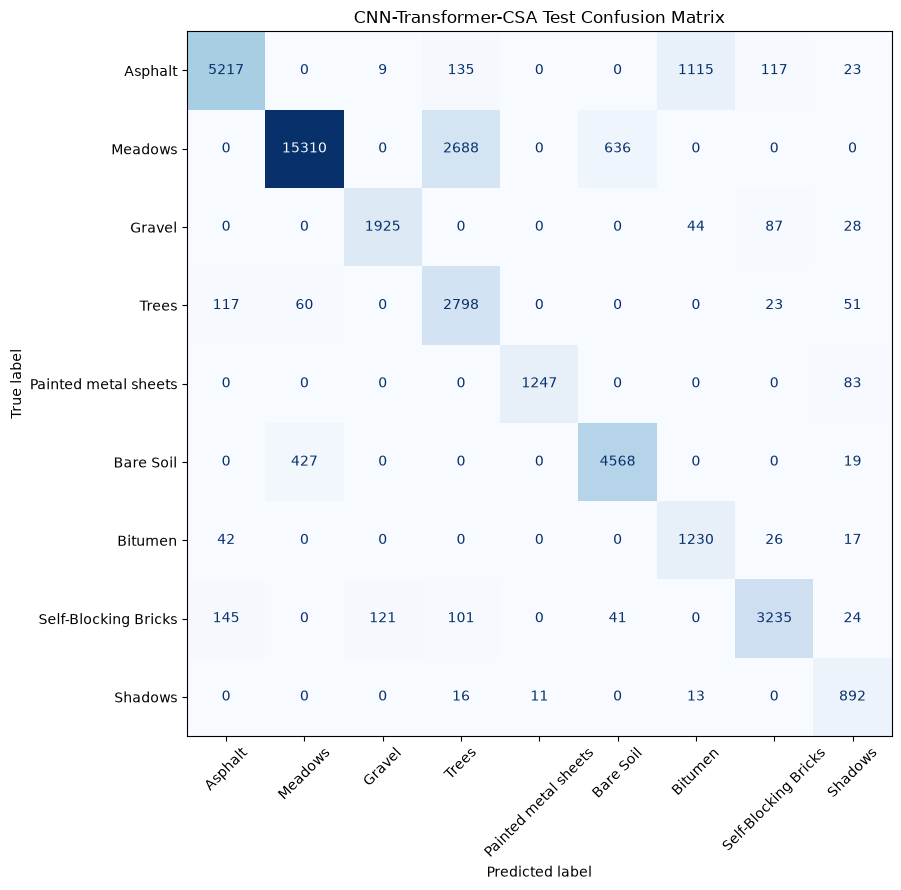

In [ ]:
# PRINT TEST METRICS AND SAVE EACH RUN'S REPORT

for run in evaluation_runs:
    training_seed = run["seed"]
    test_metrics = run["evaluation_result"]["metrics"]

    print(f"\nTraining seed {training_seed}")
    print(f"OA: {test_metrics['overall_accuracy']:.4f}")
    print(f"AA: {test_metrics['average_accuracy']:.4f}")
    print(f"Kappa: {test_metrics['kappa']:.4f}")
    print("Per-class accuracy:")
    for class_index, class_accuracy in enumerate(test_metrics["per_class_accuracy"]):
        original_label = class_index + 1
        print(f"  {original_label} {class_names[original_label]}: {class_accuracy:.4f}")

    evaluation_report_path = project_root / "outputs" / "results" / f"{run['checkpoint_path'].stem}.json"
    evaluation_report = build_evaluation_report(
        run["configuration"],
        run["checkpoint_path"],
        run["evaluation_result"],
        class_names,
    )
    if SAVE_EVALUATION_REPORT:
        save_evaluation_report(evaluation_report_path, evaluation_report)
        print("Evaluation report saved to:", evaluation_report_path)


# CALCULATE METRICS ACROSS ALL RUNS

aggregate_metrics = aggregate_classification_metrics(
    [run["evaluation_result"]["metrics"] for run in evaluation_runs]
)
print("\nAggregate metrics (mean \u00b1 sample standard deviation)")
for label, metric_name in (
    ("OA", "overall_accuracy"),
    ("AA", "average_accuracy"),
    ("Kappa", "kappa"),
):
    summary = aggregate_metrics[metric_name]
    print(f"{label}: {summary['mean']:.4f} \u00b1 {summary['std']:.4f}")

print("Per-class accuracy:")
for class_index, (mean_accuracy, std_accuracy) in enumerate(zip(
    aggregate_metrics["per_class_accuracy"]["mean"],
    aggregate_metrics["per_class_accuracy"]["std"],
)):
    original_label = class_index + 1
    print(f"  {original_label} {class_names[original_label]}: {mean_accuracy:.4f} \u00b1 {std_accuracy:.4f}")


# SAVE AGGREGATE REPORT FOR MULTI-SEED TRAINING

if TRAINING_SEED_MODE != TrainingSeedMode.ONE_FIXED_TRAIN_SEED:
    aggregate_configuration = dict(evaluation_runs[0]["configuration"])
    aggregate_configuration.pop("training_seed")
    aggregate_configuration.update({
        "num_seeds": len(training_seeds),
        "training_seeds": training_seeds,
    })
    aggregate_report = {
        "configuration": aggregate_configuration,
        "runs": [
            {
                "training_seed": run["seed"],
                "checkpoint_path": run["checkpoint_path"],
                "best_epoch": run["training_result"]["best_epoch"],
                "validation_loss": run["training_result"]["best_validation_loss"],
                "test_metrics": run["evaluation_result"]["metrics"],
            }
            for run in evaluation_runs
        ],
        "aggregate": aggregate_metrics,
    }
    seed_collection = (
        "fixed"
        if TRAINING_SEED_MODE == TrainingSeedMode.MULTI_FIXED_TRAIN_SEED
        else "random"
    )
    checkpoint_stem = evaluation_runs[0]["checkpoint_path"].stem
    training_seed_marker = f"train{training_seeds[0]}"
    training_phase_suffix = ""
    if checkpoint_stem.endswith("_compact"):
        training_seed_marker += "_compact"
        training_phase_suffix = "_ft"

    aggregate_name = (
        f"{seed_collection}{len(training_seeds)}_"
        f"{training_seeds[0]}-{training_seeds[-1]}{training_phase_suffix}"
    )
    aggregate_report_stem = checkpoint_stem.replace(
        training_seed_marker, aggregate_name
    )
    aggregate_report_path = project_root / "outputs" / "results" / f"{aggregate_report_stem}.json"
    if SAVE_EVALUATION_REPORT:
        save_evaluation_report(aggregate_report_path, aggregate_report)
        print("Aggregate report saved to:", aggregate_report_path)


# PLOT THE AGGREGATE CONFUSION MATRIX

display_names = [class_names[label] for label in LABELED_CLASS_IDS]
confusion = aggregate_metrics["confusion_matrix_sum"]
plot_confusion_matrix(confusion, display_names, MODEL_NAME)
plot_confusion_matrix(confusion, display_names, MODEL_NAME, normalized=True)



### Classification Map

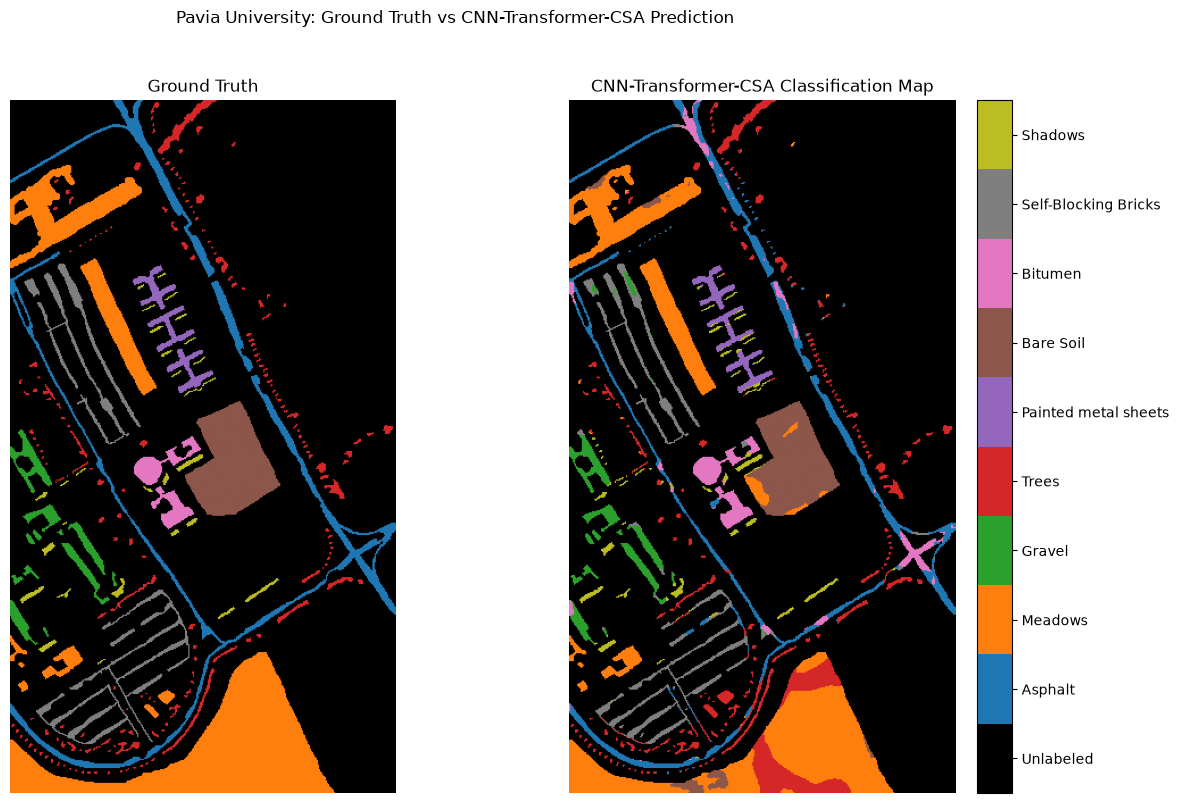

Mapped labeled pixels: 42776
Unlabeled pixels kept as background: 164624


In [ ]:
# BUILD A CLASSIFICATION MAP FOR EACH TRAINING RUN

labeled_mask = ground_truth != PaviaClass.UNLABELED
for run_index, run in enumerate(evaluation_runs, start=1):
    training_seed = run["seed"]
    print(
        f"\nBuilding classification map {run_index}/{len(evaluation_runs)} "
        f"| seed {training_seed}"
    )

    map_model = build_configured_model().to(DEVICE)
    if ARCHITECTURE.uses_adaptive_pruning:
        # Rebuild the compact model from this run's pruning checkpoint.
        mask_checkpoint = torch.load(
            run["mask_checkpoint_path"], map_location=DEVICE, weights_only=False
        )
        map_model.load_state_dict(mask_checkpoint["model_state_dict"])
        selected_band_indices = torch.as_tensor(
            mask_checkpoint["selected_band_indices"], dtype=torch.long
        )
        map_model = build_compact_pruned_model(map_model, selected_band_indices).to(DEVICE)

        if run["configuration"].get("pruning_finetune_epochs", 0) > 0:
            compact_checkpoint = torch.load(
                run["checkpoint_path"], map_location=DEVICE, weights_only=False
            )
            map_model.load_state_dict(compact_checkpoint["model_state_dict"])
    else:
        # Load this run's trained weights for the full-band model.
        checkpoint = torch.load(run["checkpoint_path"], map_location=DEVICE, weights_only=False)
        map_model.load_state_dict(checkpoint["model_state_dict"])

    # Combine this run's test predictions with predictions for the other labeled pixels.
    test_predictions = run["evaluation_result"]["predictions"]
    classification_map = build_classification_map(
        map_model,
        DEVICE,
        ground_truth,
        padded_cube,
        split_tables,
        test_predictions,
        patch_size=PATCH_SIZE,
        num_classes=NUM_CLASSES,
        batch_size=BATCH_SIZE,
        num_workers=NUM_WORKERS,
    )
    plot_classification_map(
        ground_truth,
        classification_map,
        class_names,
        NUM_CLASSES,
        f"{MODEL_NAME} (seed {training_seed})",
    )
    print("Mapped labeled pixels:", np.count_nonzero(labeled_mask))
    print("Unlabeled pixels kept as background:", (~labeled_mask).sum())
    del map_model
